# Tests de SGD (`mean_squared_error_sgd`)


## 0. Imports et chargement des données

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

from helpers import load_csv_data
from implementations import least_squares, mean_squared_error_sgd
from preprocessing import clean_and_standardize, load_feature_names
from validation import best_threshold, f1_score, split_train_validation

In [2]:
# ~45 s : lecture des CSV
x, _, y, _, _ = load_csv_data("data")
names = load_feature_names("data")

# même coupure 80/20 et même nettoyage que dans run.py
x_tr, x_val, y_tr, y_val = split_train_validation(y, x)
tx_tr, tx_val = clean_and_standardize(x_tr, x_val, names)
print("tx_tr :", tx_tr.shape, " tx_val :", tx_val.shape)

tx_tr : (262508, 154)  tx_val : (65627, 154)


In [ ]:
def f1_validation(w):
    """Seuil choisi sur le train, F1 mesuré sur la validation."""
    if not np.isfinite(w).all():
        return float("nan")
    threshold = best_threshold(y_tr, tx_tr @ w)
    return f1_score(y_val, np.where(tx_val @ w >= threshold, 1, -1))


def run_sgd(tx, gamma, max_iters, seed=1):
    """SGD reproductible : même graine -> mêmes personnes tirées."""
    np.random.seed(seed)
    w, loss = mean_squared_error_sgd(y_tr, tx, np.zeros(tx.shape[1]), max_iters, gamma)
    return w, loss


# référence : la solution exacte des moindres carrés
w_ls, loss_ls = least_squares(y_tr, tx_tr)
f1_ls = f1_validation(w_ls)
print(f"least_squares : loss = {loss_ls:.4f}, F1 validation = {f1_ls:.4f}")

least_squares : loss = 0.1370, F1 validation = 0.4129


## Test 1 : grille `gamma` × `max_iters`
On cherche la zone où SGD est stable et donne le meilleur F1. `gamma` est testé sur une échelle logarithmique.

Un F1 manquant sur le graphique = SGD a divergé (poids infinis ou `nan`).

In [ ]:
gammas = [3e-4, 1e-4, 3e-5, 1e-5]
iters_list = [10_000, 100_000, 300_000, 1_000_000]

results = {}  # (gamma, max_iters) -> (loss, F1)
for gamma in gammas:
    for max_iters in iters_list:
        start = time.time()
        with np.errstate(all="ignore"):  # pas de warnings si ça diverge
            w, loss = run_sgd(tx_tr, gamma, max_iters)
        f1 = f1_validation(w)
        results[(gamma, max_iters)] = (loss, f1)
        print(f"gamma {gamma:.0e}  iters {max_iters:>9}  loss {loss:10.4g}  F1 {f1:.4f}  ({time.time() - start:.1f}s)")

gamma 3e-04  iters     10000  loss     0.1441  F1 0.3805  (0.2s)
gamma 3e-04  iters    100000  loss       3271  F1 0.1552  (1.0s)
gamma 3e-04  iters    300000  loss  7.391e+11  F1 0.1539  (2.7s)
gamma 3e-04  iters   1000000  loss   1.49e+58  F1 0.1346  (8.5s)
gamma 1e-04  iters     10000  loss     0.1863  F1 0.3920  (0.2s)
gamma 1e-04  iters    100000  loss     0.1388  F1 0.4097  (1.0s)
gamma 1e-04  iters    300000  loss     0.1394  F1 0.3987  (2.8s)
gamma 1e-04  iters   1000000  loss      0.139  F1 0.4051  (8.7s)
gamma 3e-05  iters     10000  loss     0.3274  F1 0.3872  (0.2s)
gamma 3e-05  iters    100000  loss     0.1391  F1 0.4085  (0.9s)
gamma 3e-05  iters    300000  loss     0.1383  F1 0.4089  (2.8s)
gamma 3e-05  iters   1000000  loss     0.1381  F1 0.4098  (8.5s)
gamma 1e-05  iters     10000  loss     0.4243  F1 0.3821  (0.2s)
gamma 1e-05  iters    100000  loss     0.1848  F1 0.4034  (1.1s)
gamma 1e-05  iters    300000  loss     0.1392  F1 0.4080  (2.6s)
gamma 1e-05  iters   1000

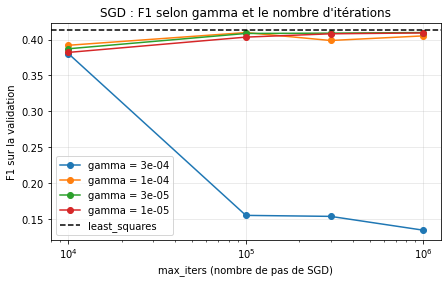

In [5]:
plt.figure(figsize=(7, 4))
for gamma in gammas:
    f1s = [results[(gamma, it)][1] for it in iters_list]
    plt.plot(iters_list, f1s, marker="o", label=f"gamma = {gamma:.0e}")
plt.axhline(f1_ls, color="black", linestyle="--", label="least_squares")
plt.xscale("log")
plt.xlabel("max_iters (nombre de pas de SGD)")
plt.ylabel("F1 sur la validation")
plt.title("SGD : F1 selon gamma et le nombre d'itérations")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Test 2 : seed

In [7]:
best_gamma, best_iters = 3e-05, 1000000  # à adapter d'après le test 1

f1s = []
for seed in range(1, 6):
    w, loss = run_sgd(tx_tr, best_gamma, best_iters, seed=seed)
    f1s.append(f1_validation(w))
    print(f"seed {seed} : loss {loss:.4f}  F1 {f1s[-1]:.4f}")
print(f"F1 = {np.nanmean(f1s):.4f} ± {np.nanstd(f1s):.4f}")

seed 1 : loss 0.1381  F1 0.4098
seed 2 : loss 0.1380  F1 0.4067
seed 3 : loss 0.1381  F1 0.4075
seed 4 : loss 0.1380  F1 0.4108
seed 5 : loss 0.1381  F1 0.4055
F1 = 0.4081 ± 0.0019


## Test 3 : chunk

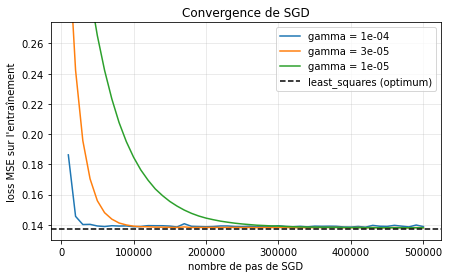

In [8]:
chunk, n_chunks = 10_000, 50
curves = {}
for gamma in [1e-4, 3e-5, 1e-5]:
    np.random.seed(1)
    w, losses = np.zeros(tx_tr.shape[1]), []
    for _ in range(n_chunks):
        with np.errstate(all="ignore"):
            w, loss = mean_squared_error_sgd(y_tr, tx_tr, w, chunk, gamma)
        losses.append(loss)
    curves[gamma] = losses

steps = chunk * np.arange(1, n_chunks + 1)
plt.figure(figsize=(7, 4))
for gamma, losses in curves.items():
    plt.plot(steps, losses, label=f"gamma = {gamma:.0e}")
plt.axhline(loss_ls, color="black", linestyle="--", label="least_squares (optimum)")
plt.ylim(loss_ls * 0.95, loss_ls * 2)
plt.xlabel("nombre de pas de SGD")
plt.ylabel("loss MSE sur l'entraînement")
plt.title("Convergence de SGD")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Test 4: train & val


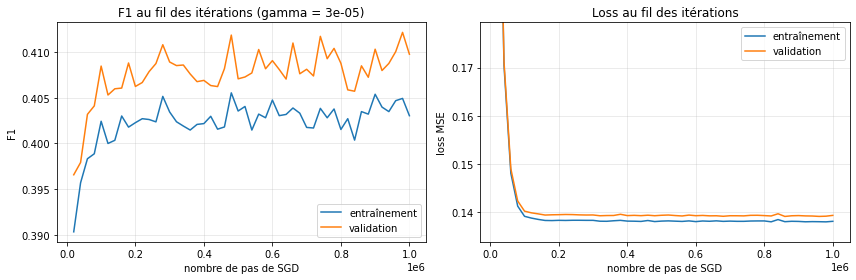

fin : F1 entraînement 0.4030, F1 validation 0.4098


In [11]:
def f1_train_and_val(w, tx_a=None, tx_b=None):
    """F1 sur l'entraînement et sur la validation, avec le seuil choisi sur l'entraînement."""
    tx_a = tx_tr if tx_a is None else tx_a
    tx_b = tx_val if tx_b is None else tx_b
    threshold = best_threshold(y_tr, tx_a @ w)
    f1_tr = f1_score(y_tr, np.where(tx_a @ w >= threshold, 1, -1))
    f1_va = f1_score(y_val, np.where(tx_b @ w >= threshold, 1, -1))
    return f1_tr, f1_va


def mse_loss(y_, tx_, w):
    return np.mean((y_ - tx_ @ w) ** 2) / 2


gamma, chunk, n_chunks = best_gamma, 20_000, 50  # best_gamma vient du test 2
np.random.seed(1)
w = np.zeros(tx_tr.shape[1])
hist = {"f1_tr": [], "f1_val": [], "loss_tr": [], "loss_val": []}
for _ in range(n_chunks):
    with np.errstate(all="ignore"):
        w, _ = mean_squared_error_sgd(y_tr, tx_tr, w, chunk, gamma)
    f1_tr, f1_va = f1_train_and_val(w)
    hist["f1_tr"].append(f1_tr)
    hist["f1_val"].append(f1_va)
    hist["loss_tr"].append(mse_loss(y_tr, tx_tr, w))
    hist["loss_val"].append(mse_loss(y_val, tx_val, w))

steps = chunk * np.arange(1, n_chunks + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(steps, hist["f1_tr"], label="entraînement")
ax1.plot(steps, hist["f1_val"], label="validation")
ax1.set_xlabel("nombre de pas de SGD")
ax1.set_ylabel("F1")
ax1.set_title(f"F1 au fil des itérations (gamma = {gamma:.0e})")
ax1.legend()
ax1.grid(alpha=0.3)
ax2.plot(steps, hist["loss_tr"], label="entraînement")
ax2.plot(steps, hist["loss_val"], label="validation")
ax2.set_ylim(min(hist["loss_tr"]) * 0.97, min(hist["loss_tr"]) * 1.3)
ax2.set_xlabel("nombre de pas de SGD")
ax2.set_ylabel("loss MSE")
ax2.set_title("Loss au fil des itérations")
ax2.legend()
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"fin : F1 entraînement {hist['f1_tr'][-1]:.4f}, F1 validation {hist['f1_val'][-1]:.4f}")

# Test 5: train curve


n =    1000 : F1 entraînement 0.5570, F1 validation 0.2962
n =    3000 : F1 entraînement 0.4624, F1 validation 0.3537
n =   10000 : F1 entraînement 0.4419, F1 validation 0.3799
n =   30000 : F1 entraînement 0.4161, F1 validation 0.3997
n =  100000 : F1 entraînement 0.4059, F1 validation 0.4062
n =  262508 : F1 entraînement 0.4034, F1 validation 0.4089


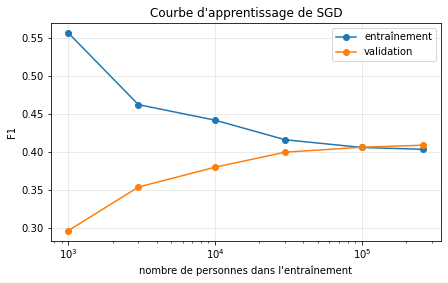

In [12]:
sizes = [1_000, 3_000, 10_000, 30_000, 100_000, len(y_tr)]
curve_tr, curve_val = [], []
for n in sizes:
    # les lignes de tx_tr sont déjà mélangées (split_train_validation) :
    # les n premières forment un sous-échantillon aléatoire
    tx_n, y_n = tx_tr[:n], y_tr[:n]
    np.random.seed(1)
    with np.errstate(all="ignore"):
        w, _ = mean_squared_error_sgd(y_n, tx_n, np.zeros(tx_n.shape[1]), 300_000, best_gamma)
    threshold = best_threshold(y_n, tx_n @ w)
    curve_tr.append(f1_score(y_n, np.where(tx_n @ w >= threshold, 1, -1)))
    curve_val.append(f1_score(y_val, np.where(tx_val @ w >= threshold, 1, -1)))
    print(f"n = {n:>7} : F1 entraînement {curve_tr[-1]:.4f}, F1 validation {curve_val[-1]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(sizes, curve_tr, marker="o", label="entraînement")
plt.plot(sizes, curve_val, marker="o", label="validation")
plt.xscale("log")
plt.xlabel("nombre de personnes dans l'entraînement")
plt.ylabel("F1")
plt.title("Courbe d'apprentissage de SGD")
plt.legend()
plt.grid(alpha=0.3)
plt.show()